
# Classification Models: Performance Evaluation & Analysis

### Student Details
* **Name: Sanket Kongare**
* **Roll Number: 18**
* **PRN: 202401040057**
* **Division: A**
* **Batch: A1**

---

## 1. Introduction & Setup
 The implementation, evaluation, and comparative analysis of four classical machine learning algorithms for classification tasks:
* Support Vector Machine (SVM)
* Decision Trees
* K-Nearest Neighbors (KNN)
* Naïve Bayes

We will create a synthetic dataset, split it into training and testing sets, train each model, and evaluate their performance using standard classification metrics (Accuracy, Precision, Recall, and F1-Score).
```

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Set random seed for reproducibility
np.random.seed(42)


## 2. Dataset Preparation
We generate a representative synthetic dataset for a binary classification task to evaluate and compare the models.


In [ ]:
# Generate a synthetic binary classification dataset
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=2,
    random_state=42
)

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features (essential for distance-based models like SVM and KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (800, 10)
Testing set shape: (200, 10)



## 3. Model Training & Evaluation
We instantiate, train, and evaluate each classifier using the scaled dataset.


In [ ]:
# Initialize the models
models = {
    "Support Vector Machine": SVC(kernel='rbf', probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Naïve Bayes": GaussianNB()
}

# Dictionary to store performance metrics
results = {}

# Train and evaluate each model
for name, model in models.items():
    # Train the model
    model.fit(X_train_scaled, y_train)

    # Make predictions
    y_pred = model.predict(X_test_scaled)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Store results
    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    }

In [ ]:
# Recalculate evaluation metrics to include Log-Loss for each classifier
from sklearn.metrics import log_loss

results = {}
confusion_matrices = {}

for name, model in models.items():
    # Get predictions
    y_pred = model.predict(X_test_scaled)

    # Get probability estimates for loss calculation
    y_prob = model.predict_proba(X_test_scaled)

    # Calculate standard evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Calculate Cross-Entropy Loss (Log-Loss)
    loss = log_loss(y_test, y_prob)

    # Store results
    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "Loss (Log-Loss)": loss
    }

    # Save confusion matrix for visualization
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

## 4. Results & Comparative Analysis
Below is the comparative summary of the performance metrics across all models.


In [ ]:
# Convert comprehensive results (including Log-Loss) to a DataFrame for visualization
df_results = pd.DataFrame(results).T
display(df_results.round(4))

,Accuracy,Precision,Recall,F1-Score,Loss (Log-Loss)
Support Vector Machine,0.92,0.9231,0.92,0.9201,0.2275
Decision Tree,0.76,0.7618,0.76,0.7602,1.2307
K-Nearest Neighbors,0.91,0.9109,0.91,0.9101,0.5622
Naïve Bayes,0.75,0.7554,0.75,0.7500,0.5142



### Confusion Matrix Visualizations
Below we plot the confusion matrices for each of the four classifiers to inspect True Positives, True Negatives, False Positives, and False Negatives.


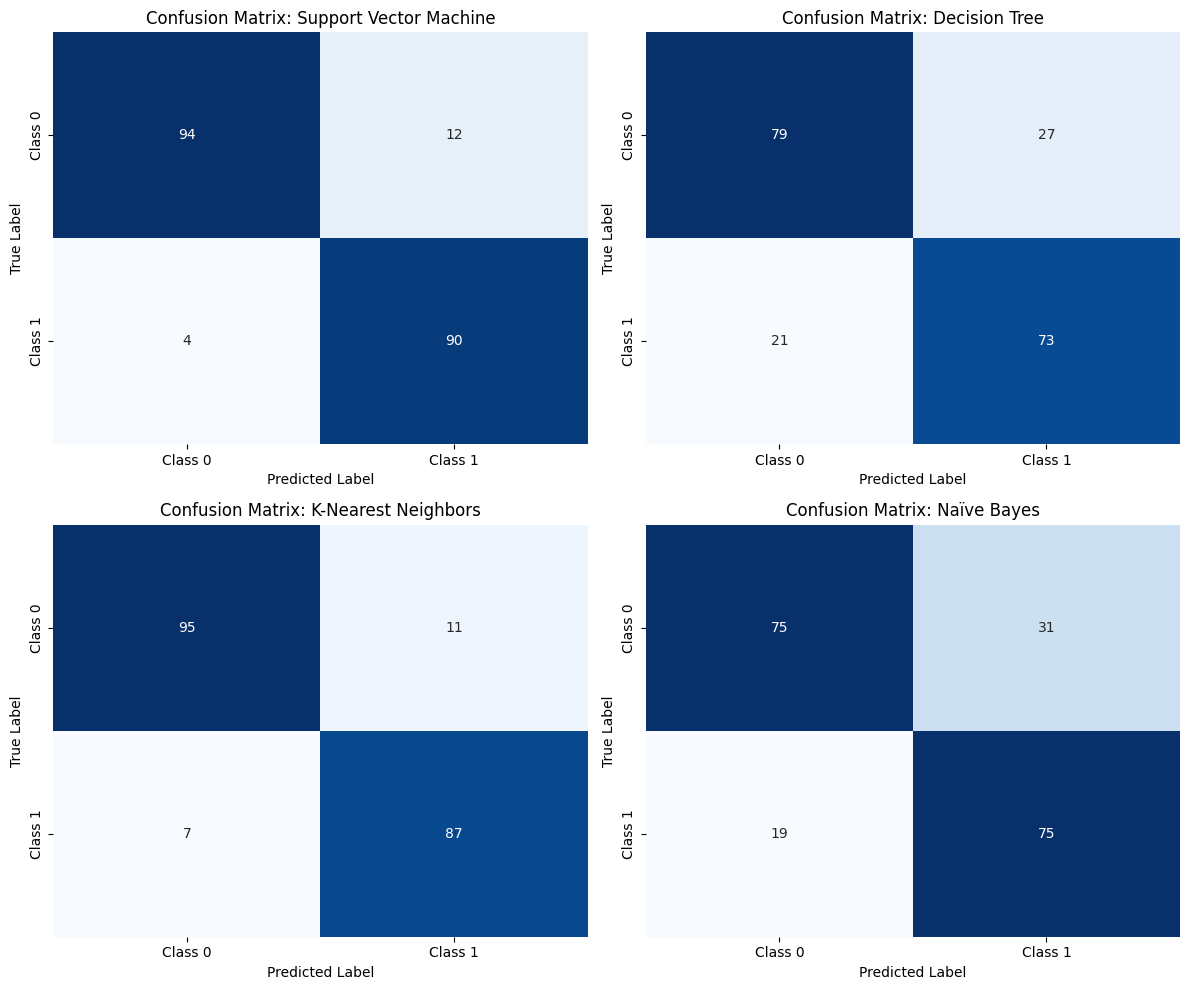

In [ ]:
# Plot Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (name, matrix) in enumerate(confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

<Figure size 1200x700 with 0 Axes>

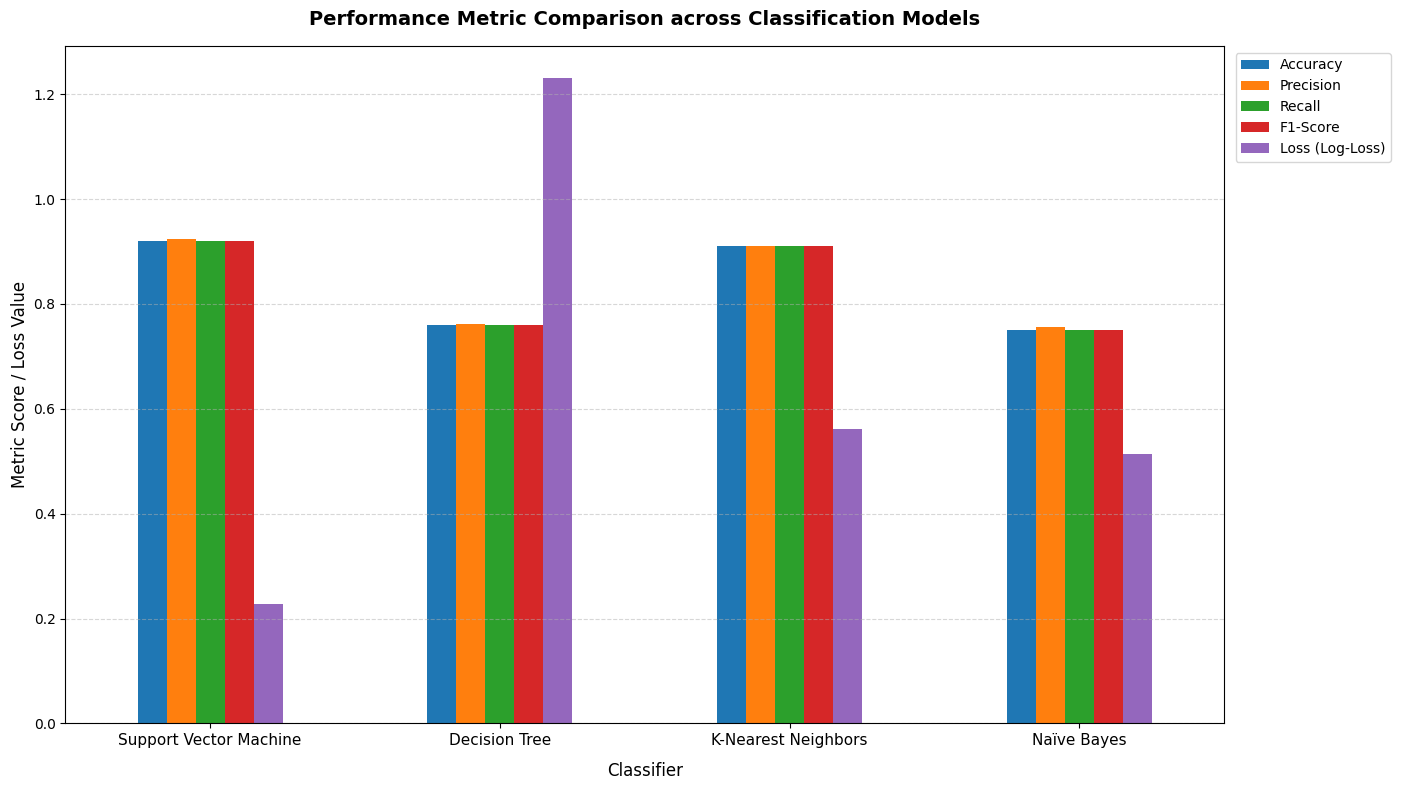

In [ ]:
# Plot all evaluated metrics (including Log-Loss) for model comparison
plt.figure(figsize=(12, 7))
df_results.plot(kind='bar', figsize=(14, 8))
plt.title('Performance Metric Comparison across Classification Models', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Classifier', fontsize=12, labelpad=10)
plt.ylabel('Metric Score / Loss Value', fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
plt.tight_layout()
plt.show()

## 5. Discussion & Suitability Analysis

### Analytical Comparison and Algorithmic Suitability

To determine the optimal classification algorithm for various real-world predictive modeling scenarios, we analyze the specific behavior, capabilities, and performance trade-offs of each evaluated classifier.

#### 1. Support Vector Machine (SVM)
* **Operational Suitability:** SVMs excel in complex classification scenarios with clear margins of separation, particularly in high-dimensional feature spaces.
* **Key Advantages:** Highly robust against the curse of dimensionality, versatile due to custom and pre-defined kernel functions (e.g., Radial Basis Function), and optimal for applications like bioinformatics or text categorization where features outnumber samples.
* **Core Constraints:** Highly computational during training on large-scale datasets; sensitive to outlier noise, which directly skews the decision boundary.

#### 2. Decision Trees
* **Operational Suitability:** Ideal for applications requiring high model transparency, structural interpretability, and sequential rule extraction.
* **Key Advantages:** Requires minimal data preprocessing (no feature scaling required), implicitly performs feature selection, and easily maps non-linear relationships without complex mathematical transformations.
* **Core Constraints:** Highly susceptible to variance and overfitting if left unconstrained; minor fluctuations in the training partition can drastically alter the tree structure.

#### 3. K-Nearest Neighbors (KNN)
* **Operational Suitability:** Best suited for low-dimensional, instance-based learning where decision boundaries are highly irregular and dynamic.
* **Key Advantages:** Simple non-parametric design that adapts instantly to new training patterns without requiring explicit model retraining (lazy learning).
* **Core Constraints:** Inference cost scales linearly with dataset size, rendering it slow for real-time predictions; highly sensitive to irrelevant features and distance distortions, requiring strict feature scaling.

#### 4. Naïve Bayes
* **Operational Suitability:** Excellent for rapid baseline classification, high-dimensional textual datasets (e.g., spam filtering, sentiment categorization), and real-time streaming pipelines.
* **Key Advantages:** Computationally efficient with minimal parameter tuning requirements, functioning robustly even with limited training observations.
* **Core Constraints:** Operates under the strict, often unrealistic assumption of absolute class-conditional independence among all input features, which can degrade predictive confidence when features are heavily correlated.
```